In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

### Data Generation

In [ ]:
import math
from abc import ABC, abstractmethod

class DataGenerator(ABC):
    def __init__(self, batch_size=64, support_set_size=10, query_set_size=10):
        self.batch_size = batch_size
        self.support_set_size = support_set_size
        self.query_set_size = query_set_size

    @abstractmethod
    def generate(self):
        # generate random batches of training data
        pass

class SineWaveDataGenerator(DataGenerator):
    def __init__(
            self, 
            x_range, 
            amplitude_range, 
            phase_range, 
            batch_size=64,
            support_set_size=10,
            query_set_size=10
        ):

        super().__init__(batch_size, support_set_size, query_set_size)
        self.x_range = x_range
        self.amplitude_range = amplitude_range
        self.phase_range = phase_range

    def create_x_y(self, amplitudes, phases, k):
        # creates input-output pairs of size (batch, k) for batch of tasks
        x =  (self.x_range[1] - self.x_range[0]) * torch.rand(self.batch_size, k) + self.x_range[0]
        x, _ = torch.sort(x, dim=1)

        # add vector phases row-wise using broadcasting
        x_plus_phase = phases.unsqueeze(1) + x

        # y = A*sin(x+phase)
        y = torch.sin(x_plus_phase)

        # element-wise multiply vector amplitudes row-wise using broadcasting
        y = amplitudes.unsqueeze(1) * y

        # add final dimension of 1 so matches expected shape of model
        return (x.unsqueeze(-1), y.unsqueeze(-1))

    def generate(self):
        """
        generate values within the specified range

        support for inner loop (for each task)
        query for outer loop (meta update)

        same amplitude and phase are used for support and query 
        """
        amplitudes = (self.amplitude_range[1] - self.amplitude_range[0]) * torch.rand(self.batch_size) + self.amplitude_range[0]
        phases = (self.phase_range[1] - self.phase_range[0]) * torch.rand(self.batch_size) + self.phase_range[0]

        x_support, y_support = self.create_x_y(amplitudes, phases, self.support_set_size)
        x_query, y_query = self.create_x_y(amplitudes, phases, self.query_set_size)

        return (x_support, y_support, x_query, y_query, amplitudes, phases)



In [63]:
# scratch work for data generation
# batch = 2
# k = 3
# A = torch.ones(batch, k)
# p = torch.tensor([5, 10])

# print(torch.sum())
# m is a 2D matrix of shape [3, 4]
m = torch.tensor([[1, 2, 3, 4],
                  [5, 6, 7, 8],
                  [9, 10, 11, 12]])

# v is a 1D vector of shape [3] (one value per row)
v = torch.tensor([10, 20, 30])

a = torch.tensor([-1, 2, -10])

# Add vector v row-wise using broadcasting
result = v.unsqueeze(1) + m

result_a = a.unsqueeze(1) * result

print(result)
print(result_a)

tensor([[11, 12, 13, 14],
        [25, 26, 27, 28],
        [39, 40, 41, 42]])
tensor([[ -11,  -12,  -13,  -14],
        [  50,   52,   54,   56],
        [-390, -400, -410, -420]])


### Model

In [3]:
class MAML(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.layers(x)

In [4]:
# input/output dim are 1 for sinusoid regression
model = MAML(1,1,40)

In [ ]:
loss_function = nn.MSELoss(reduction="none")
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [ ]:
# generate batches of sine wave data for regression
BATCH_SIZE = 25
SUPPORT_SET_SIZE = 10 # this is K
QUERY_SET_SIZE = 10

X_RANGE = [-5.0, 5.0]
AMPLITUDE_RANGE = [0.1, 5.0]
PHASE_RANGE = [0, math.pi]

data_generator = SineWaveDataGenerator(
    X_RANGE,
    AMPLITUDE_RANGE,
    PHASE_RANGE,
    batch_size=BATCH_SIZE,
    support_set_size=SUPPORT_SET_SIZE,
    query_set_size=QUERY_SET_SIZE
)

#  total number of meta-optimization steps (outer loop)
ITERATIONS = 10000

tensor([[-4.7101],
        [-4.3478],
        [-3.7852],
        [-2.5331],
        [-1.7639],
        [-1.1063],
        [-0.7505],
        [-0.6833],
        [ 0.7620],
        [ 1.1393]])
tensor(3.3036)
tensor(0.4745)


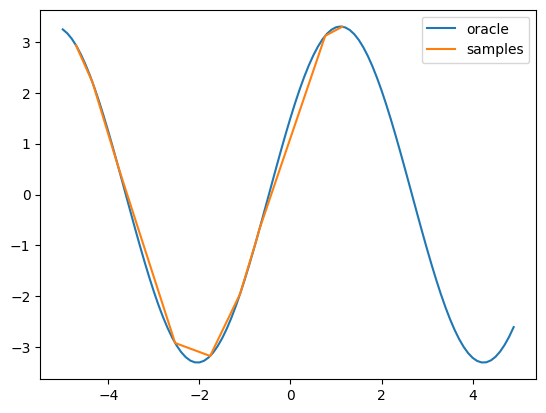

In [ ]:
# generate a batch and plot some sine waves
x_support, y_support, x_query, y_query, amplitudes, phases = data_generator.generate()
print(x_support[0])
print(amplitudes[0])
print(phases[0])

# test plotting true sine wave
x_s = torch.arange(start=-5, end=5, step=0.1)
y_s = amplitudes[0] * torch.sin(x_s + phases[0])

plt.plot(x_s, y_s, label="oracle")
plt.plot(x_support[0], y_support[0], label="samples")
plt.legend()

### Training

In [ ]:
import torch.nn.functional as F
import torch.func as tf

alpha = 0.01  # inner loop learning rate

# extract stateless functional versions of the model parameters and structure
# 'params' is a tuple of tensors, 'buffers' handles things like BatchNorm if present
params, buffers = tf.functional_call, {} 

print_loss_iters = 1000

def train(data_generator, model, optimizer, iterations):
    actual_amps_phases = []
    loss_history = []
    model.train()

    for i in range(iterations):
        weights = dict(model.named_parameters())
        optimizer.zero_grad()

        x_support, y_support, x_query, y_query, amplitudes, phases = data_generator.generate()

        # save for oracle comparison
        actual_amps_phases.append((amplitudes, phases))

        # use tf.vmap to automatically vectorize across the 25 (batchsize) tasks.
        # in_dims: (None, 0, 0) means keep the base weights global, but slice data along dim 0 (the 25 tasks)
        vectorized_adaptation = tf.vmap(adapt_single_task, in_dims=(None, 0, 0))

        # execute inner loop adaptation for all 25 tasks at once
        # 'adapted_weights_batch' will contain tensors with a new batch dimension of size 25
        adapted_weights_batch = vectorized_adaptation(weights, x_support, y_support)

        # vmap the evaluation across the 25 adapted weights and query data points
        # in_dims=(0, 0, 0) because now the weights are also batched (25 different sets of weights)
        vectorized_evaluation = tf.vmap(evaluate_single_task, in_dims=(0, 0, 0))

        # Compute the 25 meta-test losses
        query_losses = vectorized_evaluation(adapted_weights_batch, x_query, y_query) # shape: (25,)

        # average the meta-loss across all tasks
        meta_outer_loss = query_losses.mean()
        loss_history.append(meta_outer_loss.item())

        # this will backpropagate through the query evaluation, the adapted weights,
        # the inner gradients, and ultimately compute gradients for the original base weights
        meta_outer_loss.backward()

        optimizer.step()

        if i % print_loss_iters == 0:
            print(f"i={i}: {meta_outer_loss.item()}")

    return loss_history


# vectorized inner loop
# pure function that runs a single task's adaptation
# it takes the task data and base weights, computes the gradient, and returns adapted weights
def adapt_single_task(w, sx, sy):
    # local loss function that returns a scalar
    def compute_loss(weights_to_update):
        pred = tf.functional_call(model, weights_to_update, sx)
        return torch.mean((pred - sy) ** 2)  # this is a scalar

    # pass 'compute_loss' to tf.grad 
    # argnums=0 means compute gradients with respect to the first argument ('w')
    grads = tf.grad(compute_loss, argnums=0)(w)
    
    # apply the inner-loop gradient descent step
    adapted_w = {k: v - alpha * grads[k] for k, v in w.items()}
    return adapted_w


# vectorized outer loop evaluation
# evaluates query loss given a specific task's adapted weights and data
def evaluate_single_task(w, qx, qy):
    pred = tf.functional_call(model, w, qx)
    return torch.mean((pred - qy) ** 2)


i=0: 2.8885107040405273
i=1000: 0.6069110035896301
i=2000: 0.4864696264266968
i=3000: 0.5656594038009644
i=4000: 0.3401547372341156
i=5000: 0.513145923614502
i=6000: 0.3534935712814331
i=7000: 0.5350143909454346
i=8000: 0.4881674647331238
i=9000: 0.4760415256023407


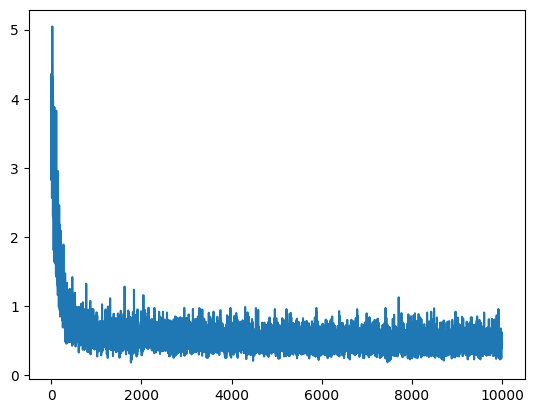

In [ ]:
loss_history = train(data_generator, model, optimizer, ITERATIONS)
plt.plot(loss_history)

### Testing

Pre-adaptation Query MSE: 4.1182
Post-adaptation Step 1 Query MSE: 0.1965
Post-adaptation Step 2 Query MSE: 0.0793
Post-adaptation Step 3 Query MSE: 0.0692


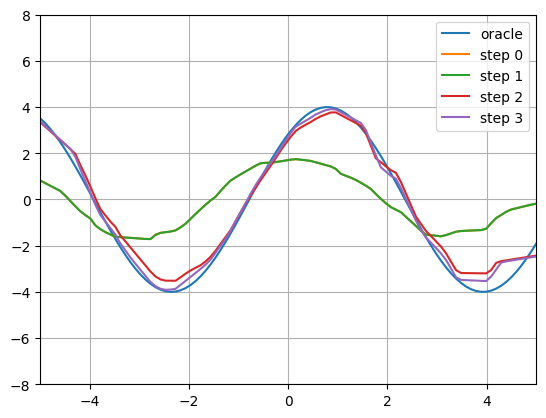

In [ ]:
# present new sine waves to model and update/plot predicted results
# and compare with true sine wave
import copy

model.eval()

target_amplitude = 4.0
target_phase = math.pi / 4

base_weights = dict(model.named_parameters())
test_support_x = torch.linspace(-5, 5, 10).view(-1, 1)
test_support_y = target_amplitude * torch.sin(test_support_x + target_phase) 

test_query_x = torch.linspace(-5, 5, 100).view(-1, 1)   # 100 dense points to plot/test
test_query_y = target_amplitude * torch.sin(test_query_x + target_phase)

predictions_list = []

plt.grid(True)
plt.xlim(-5, 5)
plt.ylim(-2*target_amplitude, 2*target_amplitude)
plt.plot(test_query_x, test_query_y, label="oracle")

# evaluate the model before adaptation
with torch.no_grad():
    # how does the meta-trained base model do without any updates
    initial_preds = tf.functional_call(model, base_weights, test_query_x)
    predictions_list.append(initial_preds.detach().numpy())
    initial_loss = F.mse_loss(initial_preds, test_query_y)
    print(f"Pre-adaptation Query MSE: {initial_loss.item():.4f}")
    plt.plot(test_query_x, initial_preds, label="step 0")

# perform 1 (or more) adaptation steps

# create a copy of the base weights to adapt specifically for this new task
adapted_weights = copy.deepcopy(base_weights)
num_test_steps = 3  

for step in range(num_test_steps):
    # enable gradients locally so we can compute the inner-loop step
    # we do not use create_graph=True because we aren't backpropagating to the base model anymore
    
    # temporarily turn on gradient tracking for the adapted weights
    for k in adapted_weights.keys():
        adapted_weights[k].requires_grad_(True)
        
    # forward pass on the small support set
    pred_support = tf.functional_call(model, adapted_weights, test_support_x)
    support_loss = F.mse_loss(pred_support, test_support_y)

    pred_query = tf.functional_call(model, adapted_weights, test_query_x)
    plt.plot(test_query_x, pred_query.detach().numpy(), label=f"step {step+1}")
    predictions_list.append(pred_query.detach().numpy())
    
    # calculate gradients of the support loss with respect to our active adapted weights
    grads = torch.autograd.grad(support_loss, adapted_weights.values())
    grads_dict = dict(zip(adapted_weights.keys(), grads))
    
    # apply standard gradient descent step (detach keeps the graph from compounding)
    with torch.no_grad():
        adapted_weights = {
            k: (v - alpha * grads_dict[k]).detach() 
            for k, v in adapted_weights.items()
        }
        
    # evaluate performance after this step
    with torch.no_grad():
        query_preds = tf.functional_call(model, adapted_weights, test_query_x)
        query_loss = F.mse_loss(query_preds, test_query_y)
        print(f"Post-adaptation Step {step + 1} Query MSE: {query_loss.item():.4f}")

plt.legend()

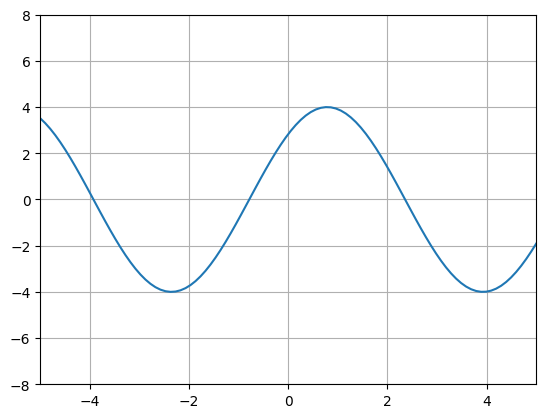

0
(100,)
1
(100,)
2
(100,)
3
(100,)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.animation import FuncAnimation

# setup the figure and axis
fig, ax = plt.subplots()
plt.grid(True)
plt.xlim(-5, 5)
plt.ylim(-2*target_amplitude, 2*target_amplitude)
ax.plot(test_query_x, test_query_y)

# initialize an empty line object (note the comma for unpacking)
line, = ax.plot([], [], lw=2, color='blue')

# define the initialization function (draws the baseline)
def init():
    line.set_data([], [])
    return line,

# define the update function (called for each frame)
def update(frame):
    # the 'frame' variable shifts the phase over time
    print(frame)
    x = test_query_x
    y = predictions_list[frame]
    print(y.squeeze().shape)
    
    line.set_data(x, y)
    return line,

# construct the animation
# 'frames' sends sequential values (0 to 2π) into the update function
ani = FuncAnimation(
    fig, 
    update, 
    frames=len(predictions_list),
    init_func=init, 
    blit=True, 
    interval=2000
)

plt.show()
writergif = animation.PillowWriter(fps=3)
ani.save('sine_wave.gif', writer=writergif)